# PRCP-1007-LiverPatientPred

## Problem Statement
The objective is to build a supervised machine-learning classification model that predicts whether a person is classified as having liver disease based on demographic information and laboratory measurements. The model is evaluated using F1-score, recall, precision, specificity, and ROC-AUC.

**Important:** This is an educational project using a small dataset. Its predictions are not a medical diagnosis and must not be used to make clinical decisions.

## 1. Import Libraries



In [ ]:
#Import the tools needed for data handling, visualization, preprocessing, model comparison, evaluation, and saving the complete pipeline.
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

## 2. Load the Dataset
This example uses the Google Drive path from the original notebook. If your file is stored somewhere else, update `file_path`. The dataset is assumed to have no header row and to follow the standard 11-column Indian Liver Patient Dataset layout.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

columns = [
    "Age", "Gender", "Total_Bilirubin", "Direct_Bilirubin",
    "Alkaline_Phosphotase", "Alamine_Aminotransferase",
    "Aspartate_Aminotransferase", "Total_Protiens", "Albumin",
    "Albumin_and_Globulin_Ratio", "Target"
]

df=pd.read_csv('/content/drive/MyDrive/Bidya/Liver Patient.csv',header=None,
    names=columns)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Mounted at /content/drive
Dataset shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


None

## 3. Exploratory Data Analysis (EDA)
Check data types, missing values, duplicate rows, and target labels before modeling. Do not impute missing values here; the pipeline will learn imputation values from the training data only.

In [ ]:
display(df.describe(include="all").T)
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Target values before mapping:", df["Target"].value_counts(dropna=False))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,583.0,NaN,NaN,NaN,44.746141,16.189833,4.0,33.0,45.0,58.0,90.0
Gender,583,2,Male,441,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Bilirubin,583.0,NaN,NaN,NaN,3.298799,6.209522,0.4,0.8,1.0,2.6,75.0
Direct_Bilirubin,583.0,NaN,NaN,NaN,1.486106,2.808498,0.1,0.2,0.3,1.3,19.7
Alkaline_Phosphotase,583.0,NaN,NaN,NaN,290.576329,242.937989,63.0,175.5,208.0,298.0,2110.0
Alamine_Aminotransferase,583.0,NaN,NaN,NaN,80.713551,182.620356,10.0,23.0,35.0,60.5,2000.0
Aspartate_Aminotransferase,583.0,NaN,NaN,NaN,109.910806,288.918529,10.0,25.0,42.0,87.0,4929.0
Total_Protiens,583.0,NaN,NaN,NaN,6.48319,1.085451,2.7,5.8,6.6,7.2,9.6
Albumin,583.0,NaN,NaN,NaN,3.141852,0.795519,0.9,2.6,3.1,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,NaN,NaN,NaN,0.947064,0.319592,0.3,0.7,0.93,1.1,2.8


Missing values per column:


,Missing Values
Age,0
Gender,0
Total_Bilirubin,0
Direct_Bilirubin,0
Alkaline_Phosphotase,0
Alamine_Aminotransferase,0
Aspartate_Aminotransferase,0
Total_Protiens,0
Albumin,0
Albumin_and_Globulin_Ratio,4


Exact duplicate rows: 13
Target values before mapping: Target
1    416
2    167
Name: count, dtype: int64



In the standard dataset, target `1` means liver disease and target `2` means no liver disease. We map these to `1` and `0`, respectively, so that the positive class (`1`) is liver disease. Rows with a missing target are not usable for supervised learning. Exact duplicates are removed to reduce repeated records.

In [ ]:
df = df.dropna(subset=["Target"]).copy()
df = df.drop_duplicates().copy()
#errors="coerce" converts it to NaN instead of raising a conversion error.
df["Target"] = pd.to_numeric(df["Target"], errors="coerce")
df = df.dropna(subset=["Target"]).copy()

target_mapping = {1: 1, 2: 0}
df["Target"] = df["Target"].map(target_mapping)

if df["Target"].isna().any():
  #raise ValueError(...) stops the code and displays an error message.
    raise ValueError("Unexpected target labels found. Check the original dataset target values.")

df["Target"] = df["Target"].astype(int)
#Standardize the text in the Gender column.
df["Gender"] = df["Gender"].astype("string").str.strip().str.title()

print("Shape after cleaning:", df.shape)
print("Target counts (1 = liver disease, 0 = no liver disease):")
#To understand the distribution of the two classes and check whether the dataset is imbalanced.
display(df["Target"].value_counts().rename(index={1: "Liver disease", 0: "No liver disease"}))

Shape after cleaning: (570, 11)
Target counts (1 = liver disease, 0 = no liver disease):


,count
Target,
Liver disease,406
No liver disease,164


## 4. Data Visualization
Visualize class balance and a few numerical distributions. These plots help describe the data; they do not by themselves establish causation or clinical usefulness.

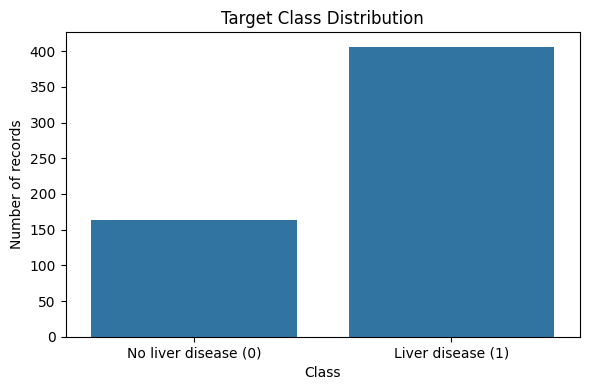

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Target")
plt.xticks([0, 1], ["No liver disease (0)", "Liver disease (1)"])
plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()



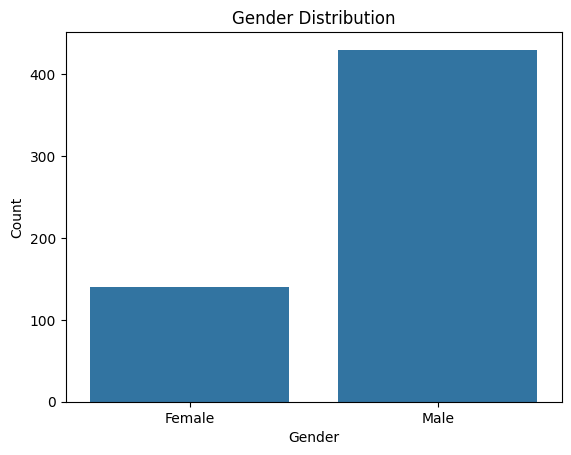

In [ ]:
#Gender Distribution
sns.countplot(x="Gender", data=df)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

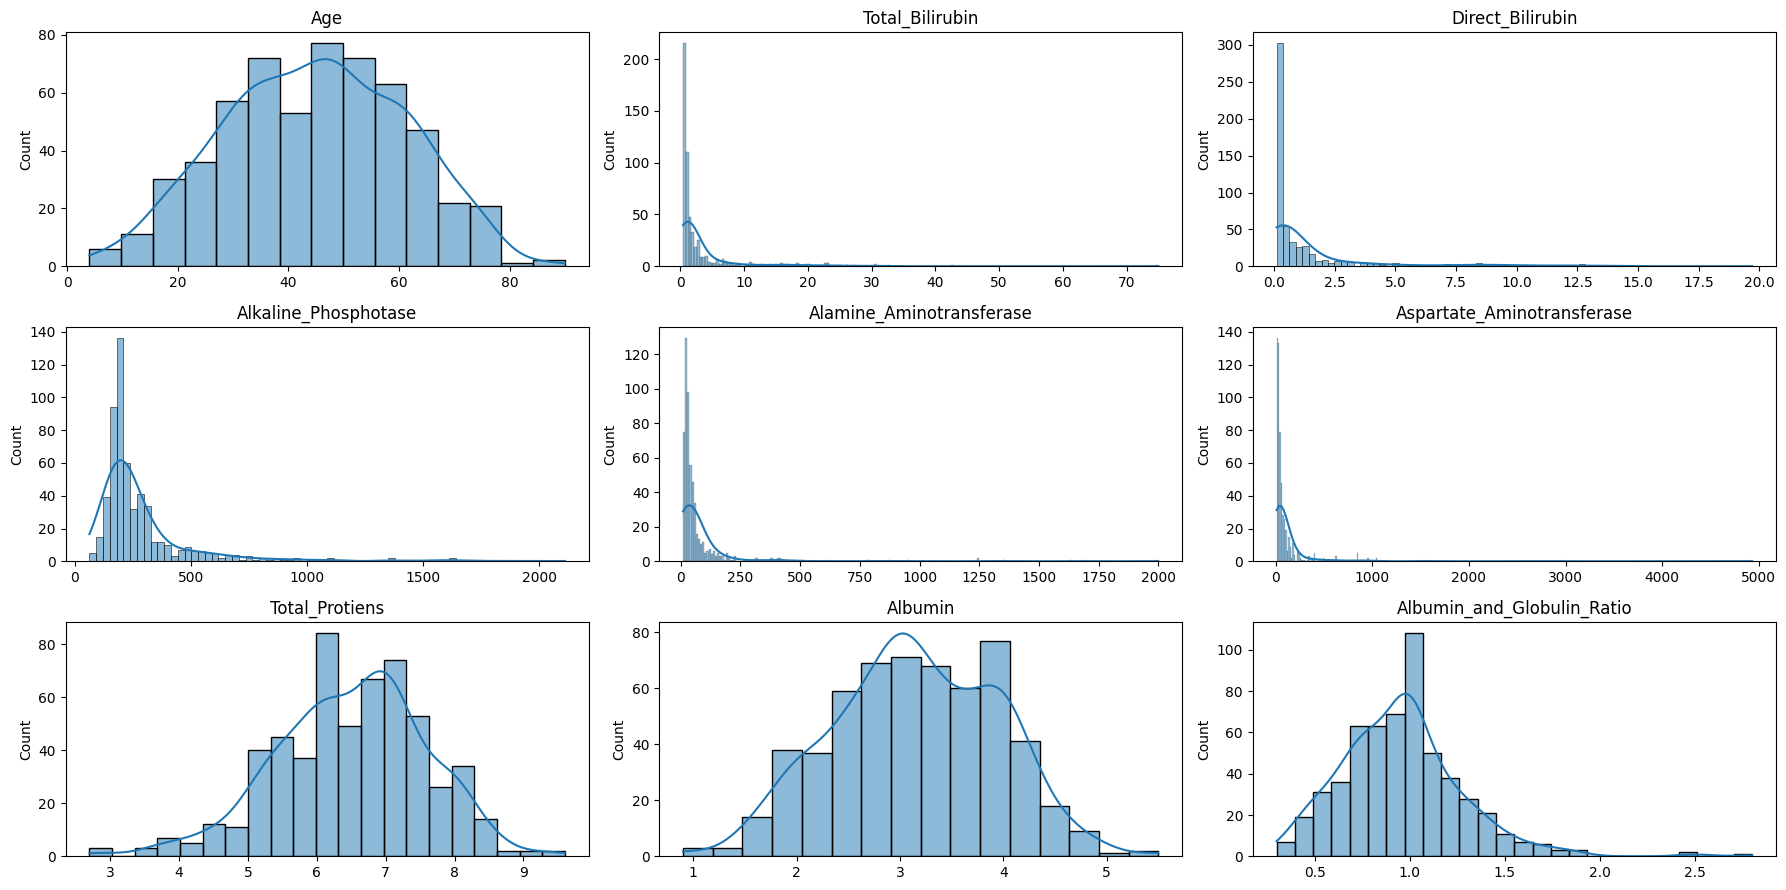

In [ ]:
#Numerical Feature Distribution
numeric_features = df.select_dtypes(
    include=np.number
).columns.drop("Target")

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 9)
)

axes = axes.flatten()

for i, feature in enumerate(numeric_features):

    sns.histplot(
        df[feature],
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

plt.tight_layout()
plt.show()

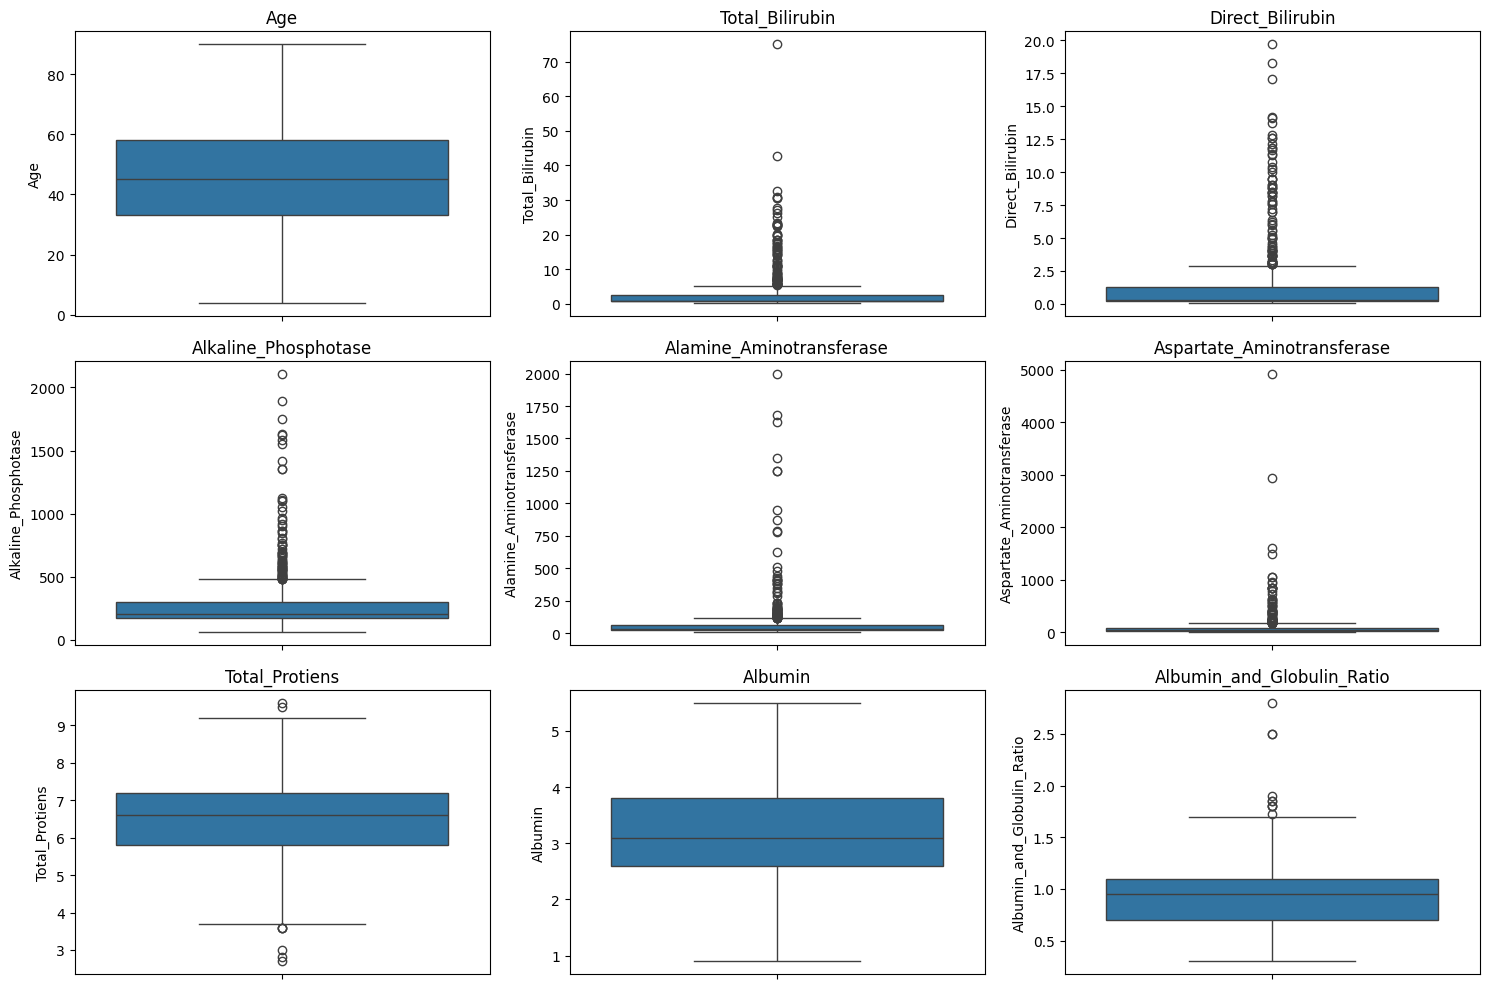

In [ ]:
#Outlier Analysis
numeric_features = df.select_dtypes(
    include=np.number
).columns.drop("Target")

plt.figure(figsize=(15, 10))

for i, column in enumerate(numeric_features):

    plt.subplot(3, 3, i + 1)

    sns.boxplot(y=df[column])

    plt.title(column)

plt.tight_layout()
plt.show()

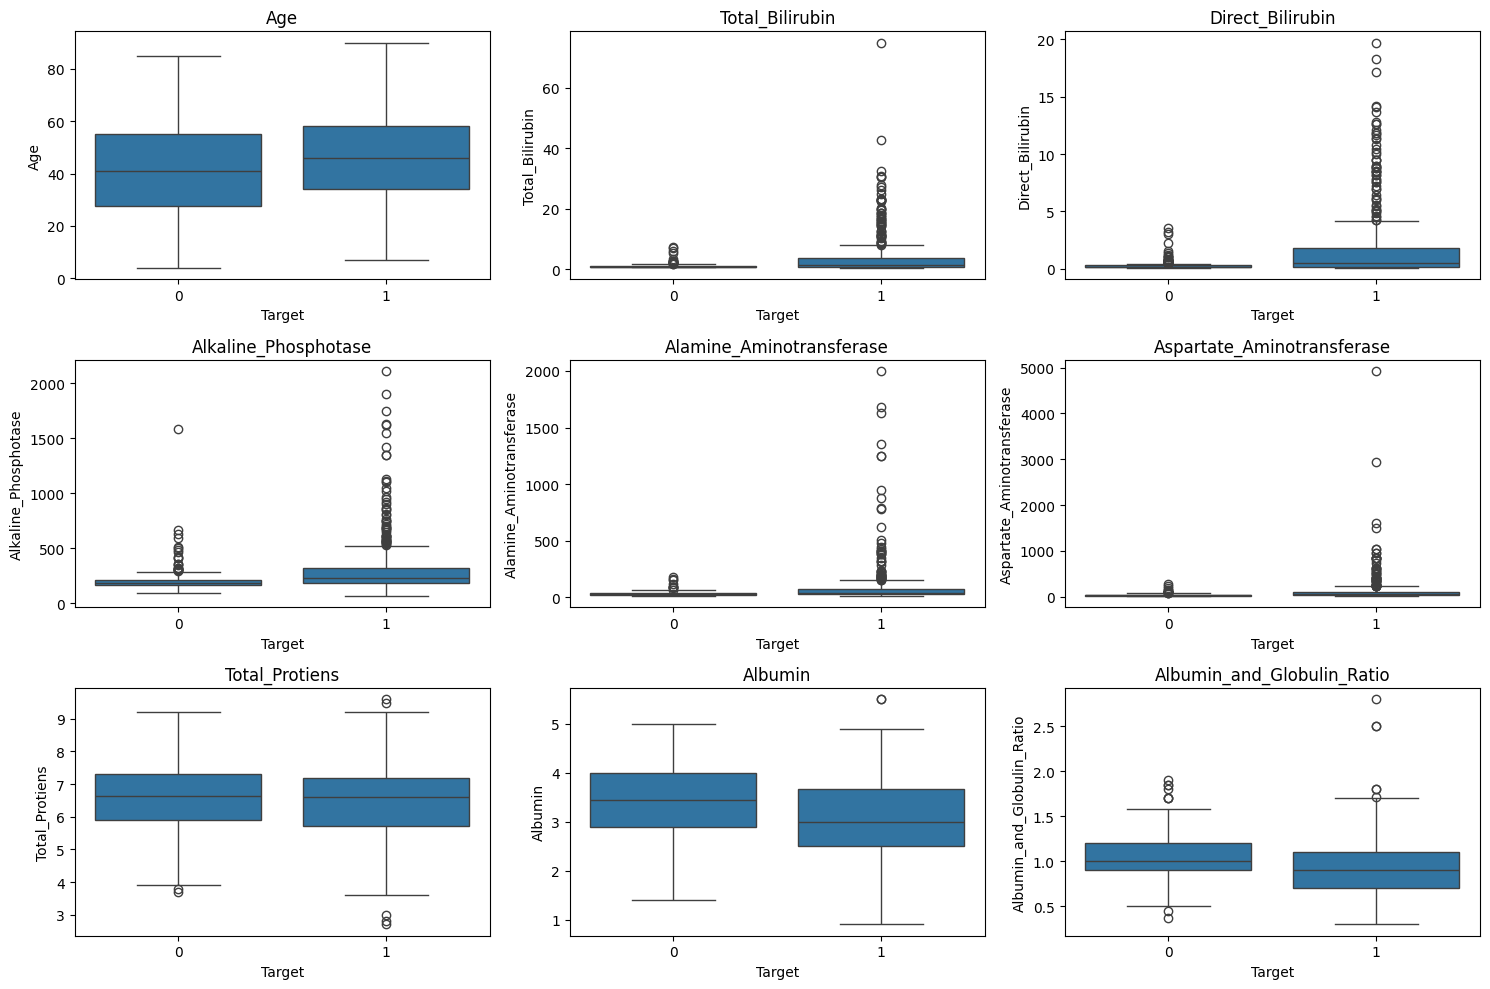

In [ ]:
#Feature vs Target Analysis
plt.figure(figsize=(15, 10))

for i, column in enumerate(numeric_features):

    plt.subplot(3, 3, i + 1)

    sns.boxplot(
        x="Target",
        y=column,
        data=df
    )

    plt.title(column)

plt.tight_layout()
plt.show()

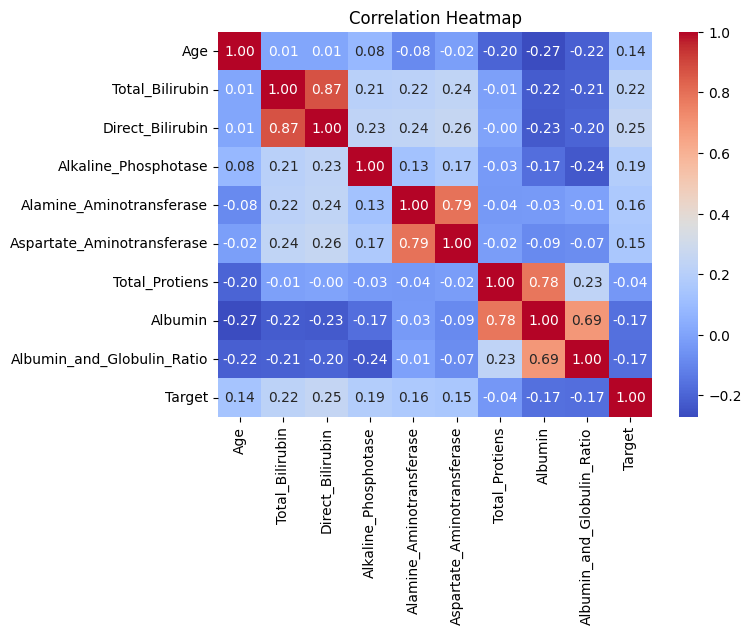

In [ ]:
#Correlation Heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## 5. Data Preprocessing
The test set is held out for the final evaluation. Stratification preserves approximately the same target-class proportions in both sets. All preprocessing and model selection are performed using the training set only.

In [ ]:
X = df.drop(columns="Target")
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    #stratify=y helps maintain this balance when splitting the data.
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

Training set: (456, 10)
Test set: (114, 10)
Training class proportions:


,Proportion
Target,
1,0.712719
0,0.287281



Numerical missing values are replaced with the training median and then scaled. Categorical missing values are replaced with the most frequent training category and encoded using one-hot encoding. Keeping these steps inside a pipeline prevents test-set information from leaking into training.

In [ ]:
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
#A pipeline automates the steps, and a ColumnTransformer decides which steps to apply to which columns.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']
Categorical features: ['Gender']


## 6. Model Building and Training
Compare several models using the same training folds. F1, recall, precision, and ROC-AUC are measured with stratified cross-validation. The baseline model provides a simple reference point; a useful model should outperform it.

In [ ]:
#shuffle=True: Shuffles the data before splitting.random_state=42: Helps you get the same splits when you run the code again.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    #class_weight="balanced": Helps certain models give more importance to the less common class.max_iter=3000: Allows Logistic Regression up to 3,000 iterations to find a solution.
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42),
    #n_neighbors=7: KNN considers the 7 nearest training examples.
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    #n_estimators=300: Random Forest uses 300 decision trees.
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    #probability=True: Enables SVM to provide probability estimates, which are needed for ROC-AUC scoring in this setup.
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Support Vector Machine": SVC(
        probability=True, class_weight="balanced", random_state=42
    )
}

scoring = {
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

comparison_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    scores = cross_validate(
        pipe, X_train, y_train,
        #n_jobs=-1: Random Forest uses all available CPU cores for parallel processing.
        cv=cv, scoring=scoring, n_jobs=-1,
        error_score="raise"
    )
    comparison_rows.append({
        "Model": name,
        "Mean CV F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
        "Mean CV Precision": scores["test_precision"].mean(),
        "Mean CV Recall": scores["test_recall"].mean(),
        "Mean CV ROC-AUC": scores["test_roc_auc"].mean()
    })
    #reset_index(drop=True): Resets the row numbers after sorting.

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by="Mean CV F1", ascending=False
).reset_index(drop=True)
#.round(3) rounds the numerical results to three decimal places.
display(comparison_df.round(3))

,Model,Mean CV F1,CV F1 Std,Mean CV Precision,Mean CV Recall,Mean CV ROC-AUC
0,Dummy Baseline,0.832,0.002,0.713,1.000,0.500
1,Random Forest,0.813,0.022,0.744,0.895,0.713
2,Gradient Boosting,0.797,0.027,0.754,0.846,0.700
3,K-Nearest Neighbors,0.789,0.020,0.739,0.846,0.626
4,Decision Tree,0.765,0.041,0.765,0.769,0.591
5,Logistic Regression,0.687,0.054,0.863,0.575,0.718
6,Support Vector Machine,0.640,0.054,0.890,0.505,0.714


The Dummy Classifier achieved a relatively high F1-score but an ROC-AUC of 0.500, indicating that it has no discriminative ability beyond random ranking. This is because the model uses a simple majority-class prediction strategy rather than learning meaningful patterns from patient data. Therefore, the F1-score alone does not reflect reliable performance, and the Dummy Classifier serves as a baseline for comparison with other machine learning models.

## 7. Hyperparameter Tuning
Tune Random Forest and SVM with grid search, selecting by cross-validated F1-score. The test set is not used for hyperparameter selection. If this takes too long on your computer, reduce the parameter grids.

In [ ]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1))
])
#n_estimators	Number of decision trees: try 200 and 400.
#max_depth	Maximum depth of each tree: unlimited (None), 8, or 15.
#min_samples_split	Minimum number of samples required to split a node: 2 or 5.
#min_samples_leaf	Minimum number of samples required in a leaf: 1 or 2.

rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 8, 15],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}


#refit=True: After finding the best combination, trains the pipeline again on all the training data.
#rf_param_grid: All parameter combinations to test.
#scoring="f1": Selects the combination with the best average F1-score.

rf_search = GridSearchCV(
    rf_pipeline, rf_param_grid,
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)

svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(probability=True, class_weight="balanced", random_state=42))
])

#C:	      Controls the trade-off between classification errors and a more complex decision boundary.
#kernel:	kernel	Determines the type of decision boundary. linear uses a straight boundary; rbf can model more complex boundaries.
#gamma:	  Controls how far the influence of individual training points extends when using the RBF kernel.

svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["rbf", "linear"],
    "model__gamma": ["scale", "auto"]
}

svm_search = GridSearchCV(
    svm_pipeline, svm_param_grid,
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
svm_search.fit(X_train, y_train)

tuning_results = pd.DataFrame([
    {"Model": "Tuned Random Forest", "Best CV F1": rf_search.best_score_,
     "Best Parameters": rf_search.best_params_},
    {"Model": "Tuned SVM", "Best CV F1": svm_search.best_score_,
     "Best Parameters": svm_search.best_params_}
]).sort_values("Best CV F1", ascending=False)
display(tuning_results)

,Model,Best CV F1,Best Parameters
0,Tuned Random Forest,0.813895,"{'model__max_depth': 15, 'model__min_samples_l..."
1,Tuned SVM,0.663609,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."


## 8. Select the Final Model
Choose between the tuned candidates based on training-only cross-validation F1. This avoids choosing a model simply because it happened to score well on the test set.

In [ ]:
candidate_searches = {
    "Tuned Random Forest": rf_search,
    "Tuned SVM": svm_search
}

best_name = max(candidate_searches, key=lambda name: candidate_searches[name].best_score_)
final_model = candidate_searches[best_name].best_estimator_

print("Selected final model:", best_name)
print("Best mean CV F1-score:", round(candidate_searches[best_name].best_score_, 4))
print("Best parameters:", candidate_searches[best_name].best_params_)

Selected final model: Tuned Random Forest
Best mean CV F1-score: 0.8139
Best parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}


## 9. Final Model Evaluation
Evaluate the selected model once on the held-out test set. The positive class is liver disease (`1`). Recall is especially important to inspect because false negatives mean diseased cases missed by the model. No single metric is sufficient.

,Accuracy,Precision (disease),Recall (disease),F1-score (disease),Specificity (no disease),ROC-AUC
0,0.737,0.748,0.951,0.837,0.212,0.764


Classification report:
                      precision    recall  f1-score   support

No liver disease (0)       0.64      0.21      0.32        33
   Liver disease (1)       0.75      0.95      0.84        81

            accuracy                           0.74       114
           macro avg       0.69      0.58      0.58       114
        weighted avg       0.72      0.74      0.69       114



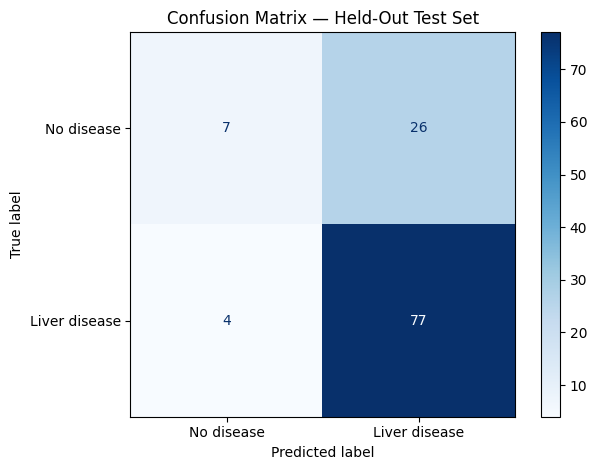

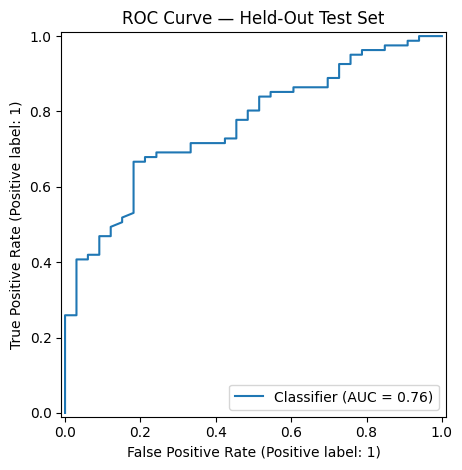

In [ ]:
y_pred = final_model.predict(X_test)
y_probability = final_model.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
specificity = tn / (tn + fp) if (tn + fp) else np.nan

test_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (disease)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (disease)": recall_score(y_test, y_pred, zero_division=0),
    "F1-score (disease)": f1_score(y_test, y_pred, zero_division=0),
    "Specificity (no disease)": specificity,
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}])
display(test_metrics.round(3))

print("Classification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["No liver disease (0)", "Liver disease (1)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["No disease", "Liver disease"],
    #cmap="Blues": Uses a blue color scheme.
    cmap="Blues",
    #values_format="d": Displays whole-number counts.
    values_format="d"
)
plt.title("Confusion Matrix — Held-Out Test Set")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve — Held-Out Test Set")
#plt.tight_layout(): Adjusts spacing.
plt.tight_layout()
plt.show()

## 10. Prediction on New Patient Data
Enter values in the original feature format. Do not manually impute or scale the values; the saved pipeline handles preprocessing. The example values below are illustrative only and do not represent a real patient or validated medical advice.

In [ ]:
new_patient = pd.DataFrame([{
    "Age": 45,
    "Gender": "Male",
    "Total_Bilirubin": 1.0,
    "Direct_Bilirubin": 0.3,
    "Alkaline_Phosphotase": 200,
    "Alamine_Aminotransferase": 30,
    "Aspartate_Aminotransferase": 35,
    "Total_Protiens": 6.8,
    "Albumin": 3.4,
    "Albumin_and_Globulin_Ratio": 1.0
}])

# Ensure the columns are in the same order as the training features.
new_patient = new_patient[X.columns]

prediction = int(final_model.predict(new_patient)[0])
probability = float(final_model.predict_proba(new_patient)[0, 1])

print("Predicted class:", prediction)
print("Model-estimated probability for liver disease:", f"{probability:.1%}")

if prediction == 1:
    print("Model output: Liver disease class (1)")
else:
    print("Model output: No liver disease class (0)")

print("This is an educational model output, not a diagnosis.")

Predicted class: 1
Model-estimated probability for liver disease: 64.1%
Model output: Liver disease class (1)
This is an educational model output, not a diagnosis.


## 11. Save the Complete Pipeline
Save the entire pipeline so that imputation, encoding, scaling, and prediction use the same fitted transformations later. Only use the model on compatible feature columns.

In [ ]:
model_path = "liver_patient_prediction_pipeline.joblib"
joblib.dump(final_model, model_path)
print(f"Saved complete pipeline to: {model_path}")

# Optional: reload it and verify that it can predict.
loaded_model = joblib.load(model_path)
assert np.array_equal(final_model.predict(X_test), loaded_model.predict(X_test))
print("Reload verification passed.")

Saved complete pipeline to: liver_patient_prediction_pipeline.joblib
Reload verification passed.


## Challenges Faced and Techniques Used

### a) Missing Values
Missing values were handled using `SimpleImputer`, with median imputation for numerical features and most-frequent imputation for categorical features. This helped ensure consistent data preprocessing.

### b) Categorical Variables
The categorical feature `Gender` was converted into a numerical representation using `OneHotEncoder`. This enabled the machine learning models to process categorical data effectively.

### c) Skewed Target Variable
The target variable represents two classes: liver disease and no liver disease. Class distribution was considered during model evaluation, and stratified splitting and cross-validation were used to preserve class proportions.

### d) Outliers
Numerical features were examined to identify potential outliers. Since extreme values may represent meaningful medical measurements, they were not automatically removed without justification.

### e) Feature Engineering
The available patient features were reviewed and prepared for modelling. Numerical features were standardized using `StandardScaler`, while categorical features were encoded through a preprocessing pipeline.

### f) Model Selection
Multiple classification algorithms were compared using stratified cross-validation. Models were evaluated using F1-score, precision, recall, and ROC-AUC. Hyperparameter tuning was performed on selected models to improve performance, and the final model was evaluated on a separate test set.

## 12. Final Conclusion
This project compares multiple classification algorithms using stratified cross-validation and selects a tuned model based on F1-score. Final performance is reported on a held-out test set using F1-score, precision, recall, specificity, and ROC-AUC. Results should be interpreted cautiously because the dataset is small and may not represent other populations. The model is for educational use only and is not a substitute for professional medical assessment.

## Streamlit App Screenshots

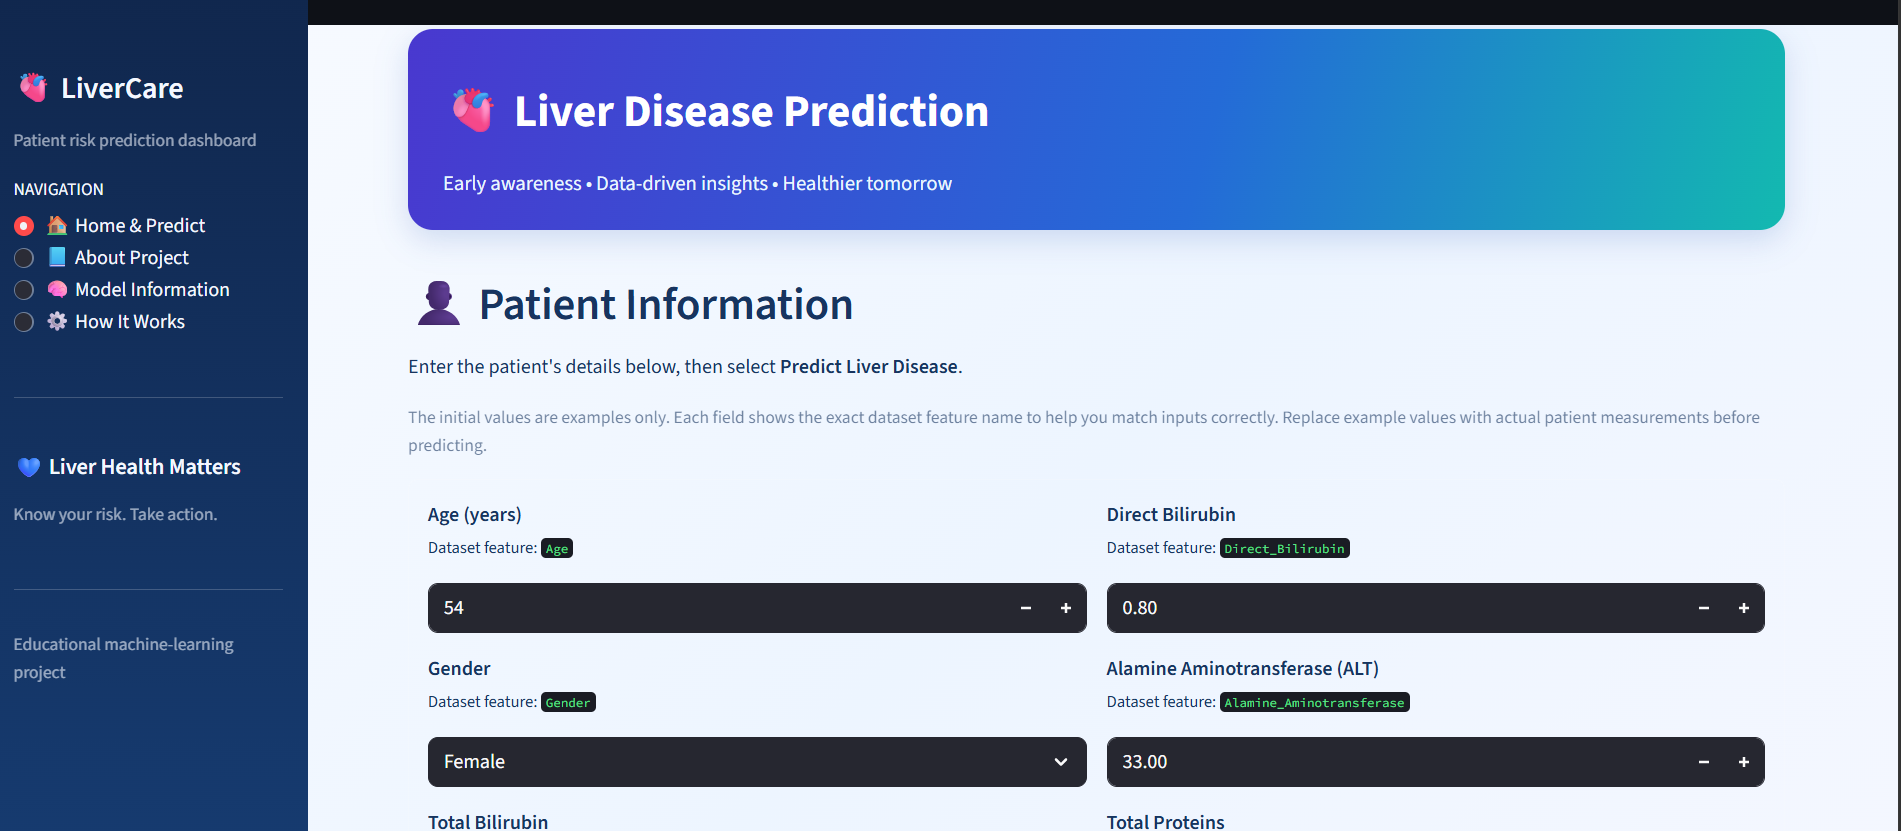

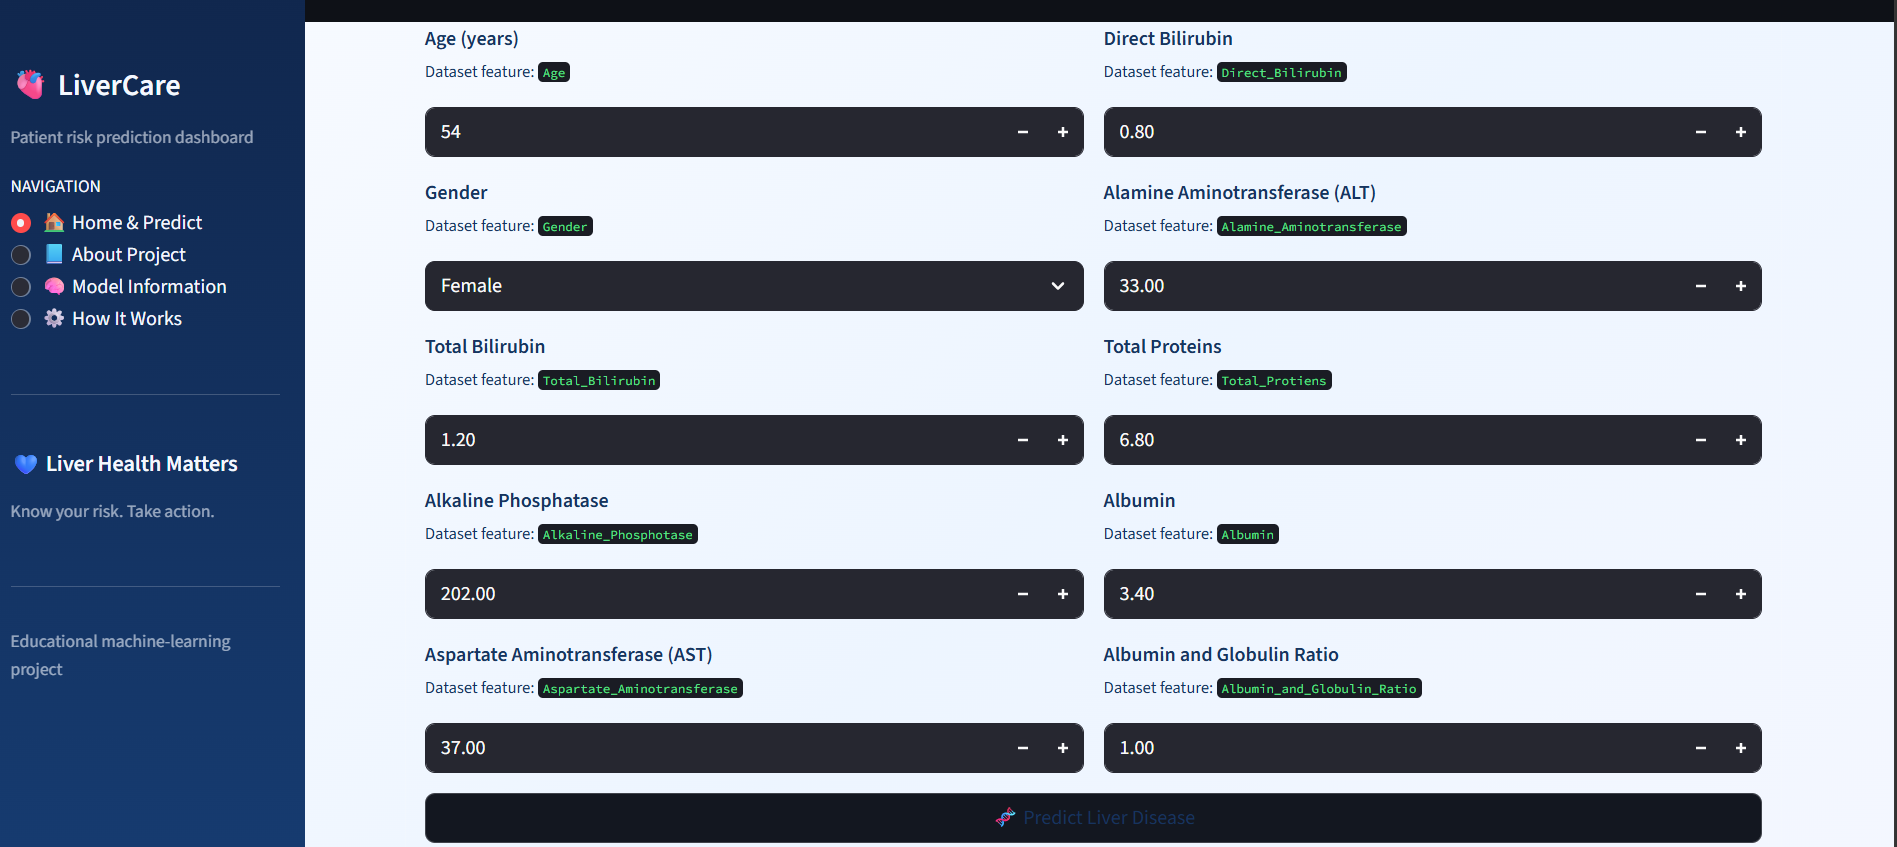

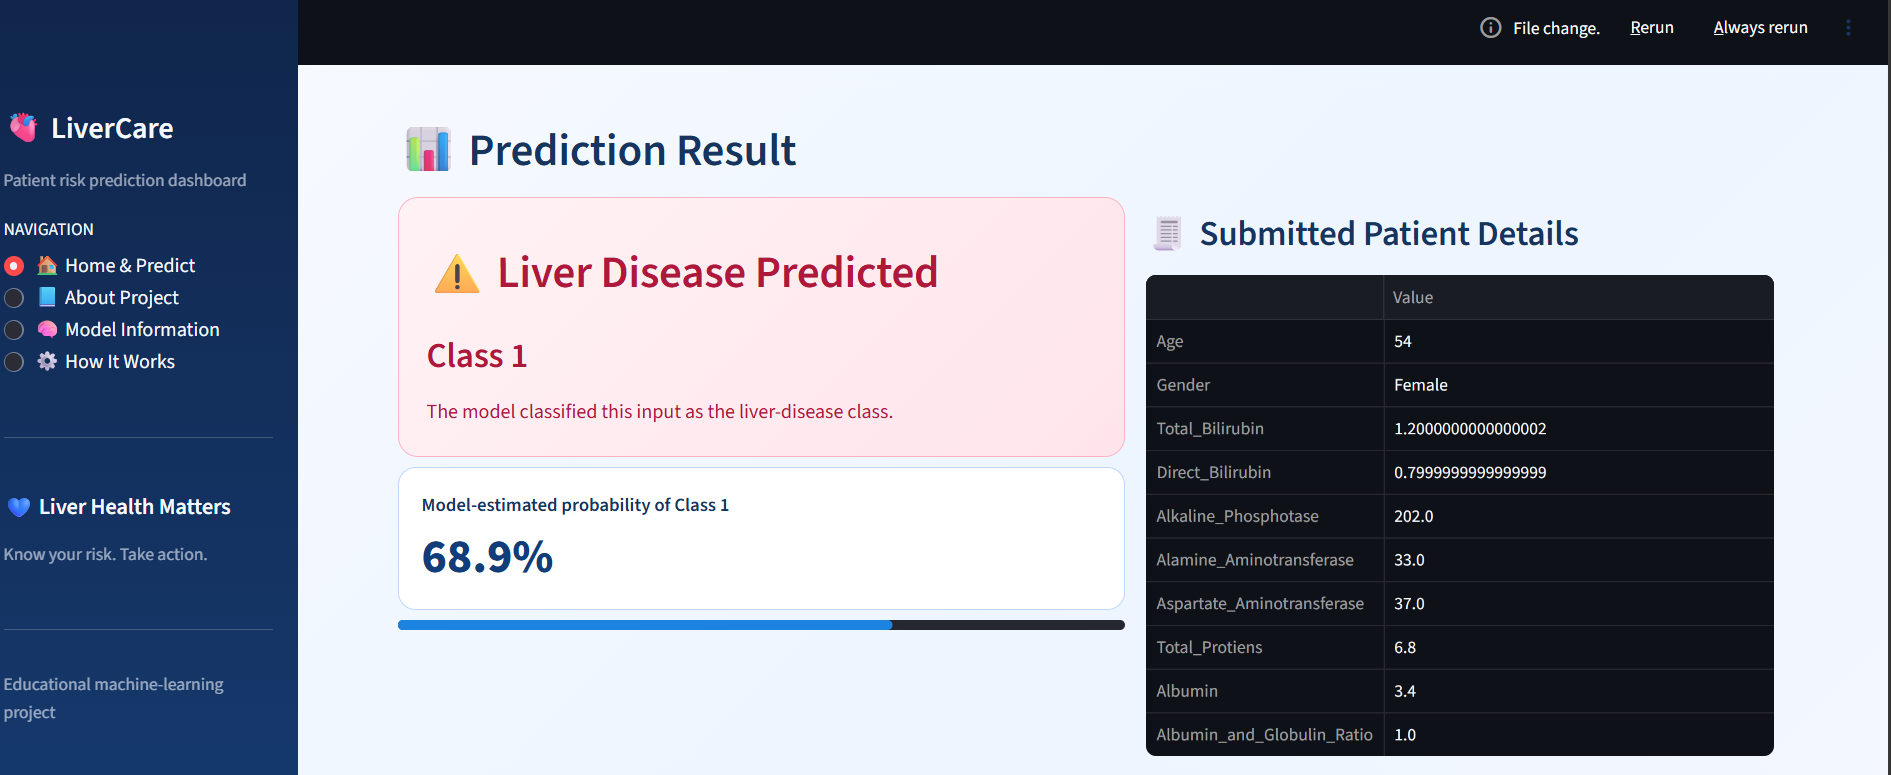

In [ ]:
import os

os.listdir()
from IPython.display import Image, display

display(Image('/content/drive/MyDrive/Bidya/datamites_priject _dataset/liver1.png'))
display(Image('/content/drive/MyDrive/Bidya/datamites_priject _dataset/liver2.png'))
display(Image('/content/drive/MyDrive/Bidya/datamites_priject _dataset/liver3.png'))


## Streamlit Code

In [ ]:
'''import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Liver Disease Prediction",
    page_icon="🫀",
    layout="wide",
    initial_sidebar_state="expanded",
)

MODEL_PATH = Path(__file__).parent / "liver_patient_prediction_pipeline.joblib"

# ---------- Styling ----------
st.markdown("""
<style>
/* Keep text readable when Streamlit is using dark mode */
.stApp, [data-testid="stAppViewContainer"], [data-testid="stMain"], section.main {
    background: linear-gradient(135deg, #f7faff 0%, #edf5ff 52%, #f4f7ff 100%);
    color: #17345f !important;
}
section.main p, section.main li, section.main label,
section.main .stMarkdown, section.main [data-testid="stWidgetLabel"],
section.main [data-testid="stCaptionContainer"], section.main h1,
section.main h2, section.main h3, section.main h4, section.main h5 {
    color: #17345f !important;
}
section.main [data-testid="stWidgetLabel"] p,
section.main [data-testid="stWidgetLabel"] label {
    color: #17345f !important;
}
section.main input, section.main textarea,
section.main [data-baseweb="select"] > div,
section.main [data-baseweb="input"] > div {
    background-color: #ffffff !important;
    color: #17345f !important;
    border-color: #bdd4f7 !important;
}
section.main input::placeholder, section.main textarea::placeholder {
    color: #6b7f9e !important;
}
section.main [data-baseweb="select"] *,
section.main [data-baseweb="input"] * {
    color: #17345f !important;
}
section.main [data-testid="stDataFrame"] { background: #ffffff !important; }

section.main [data-testid="stAlert"] p { color: #17345f !important; }

/* Make the class-probability card and percentage clearly visible */
section.main [data-testid="stMetric"] {
    background: #ffffff !important;
    border: 1px solid #bfd7ff !important;
    border-radius: 14px !important;
}
section.main [data-testid="stMetric"] label,
section.main [data-testid="stMetricLabel"],
section.main [data-testid="stMetricLabel"] p {
    color: #25466f !important;
    opacity: 1 !important;
}
section.main [data-testid="stMetric"] *,
section.main [data-testid="stMetricLabel"] *,
section.main [data-testid="stMetricValue"] *,
section.main [data-testid="stMetricDelta"] * {
    color: #123d7a !important;
    opacity: 1 !important;
    -webkit-text-fill-color: #123d7a !important;
}
section.main [data-testid="stMetricLabel"],
section.main [data-testid="stMetricLabel"] p {
    color: #25466f !important;
    opacity: 1 !important;
    -webkit-text-fill-color: #25466f !important;
}
section.main [data-testid="stMetricValue"],
section.main [data-testid="stMetricValue"] div,
section.main [data-testid="stMetricValue"] p {
    color: #123d7a !important;
    opacity: 1 !important;
    -webkit-text-fill-color: #123d7a !important;
    font-weight: 800 !important;
}
section.main [data-testid="stProgress"] div[role="progressbar"] {
    background-color: #d7e4f5 !important;
}
section.main [data-testid="stProgress"] div[role="progressbar"] > div {
    background: linear-gradient(90deg, #365cf5, #08cfa6) !important;
}

[data-testid="stSidebar"] {
    background: linear-gradient(180deg, #10264c 0%, #163b70 100%);
}
[data-testid="stSidebar"] * { color: #f4f8ff !important; }
.hero {
    padding: 24px 28px; border-radius: 20px; color: white; margin-bottom: 22px;
    background: linear-gradient(105deg, #4938cf 0%, #246bd7 58%, #13b9b0 100%);
    box-shadow: 0 8px 24px rgba(38, 85, 180, .18);
}
.hero h1 { font-size: 2.25rem; margin: 0; }
.hero p { font-size: 1.03rem; margin: 7px 0 0 0; color: #eaf7ff; }
.section-card {
    background: rgba(255,255,255,.92); padding: 20px 22px; border-radius: 16px;
    border: 1px solid #d6e5ff; box-shadow: 0 4px 15px rgba(35, 82, 150, .06);
}
.small-muted { color: #5e7294; font-size: .9rem; }
.result-good {
    padding: 22px; border-radius: 16px; border: 1px solid #8fe0c1;
    background: linear-gradient(135deg,#edfff7,#dff9ed); color: #08784c;
}
.result-risk {
    padding: 22px; border-radius: 16px; border: 1px solid #ffb3c1;
    background: linear-gradient(135deg,#fff2f4,#ffe5eb); color: #b0183b;
}
div.stButton > button {
    background: linear-gradient(90deg,#365cf5,#08cfa6); color: white;
    border: 0; border-radius: 10px; font-weight: 700; padding: .72rem 1rem;
}
div.stButton > button:hover { color: white; border: 1px solid #1dbba8; }
div[data-testid="stMetric"] {
    background: white; border: 1px solid #d9e7ff; padding: 14px; border-radius: 13px;
}
</style>
""", unsafe_allow_html=True)

# ---------- Sidebar ----------
with st.sidebar:
    st.markdown("# 🫀 LiverCare")
    st.caption("Patient risk prediction dashboard")
    page = st.radio(
        "NAVIGATION",
        ["🏠 Home & Predict", "📘 About Project", "🧠 Model Information", "⚙️ How It Works"],
        label_visibility="visible",
    )
    st.markdown("---")
    st.markdown("### 💙 Liver Health Matters")
    st.caption("Know your risk. Take action.")
    st.markdown("---")
    st.caption("Educational machine-learning project")

st.markdown("""
<div class="hero">
  <h1>🫀 Liver Disease Prediction</h1>
  <p>Early awareness • Data-driven insights • Healthier tomorrow</p>
</div>
""", unsafe_allow_html=True)

if page == "📘 About Project":
    st.markdown("## 📘 About This Project")
    st.markdown("""
    <div class="section-card">
    This machine-learning project demonstrates how patient measurements can be passed to a trained
    classification pipeline to estimate a liver-disease class. It includes input validation,
    preprocessing, prediction, and a clear explanation of the result.
    <br><br><b>Target labels used in this project:</b> Class 1 = liver disease; Class 0 = no liver disease.
    </div>
    """, unsafe_allow_html=True)
    st.markdown("### Key features")
    a,b,c = st.columns(3)
    a.info("🧹 **Preprocessing**\n\nMissing-value handling and feature transformations are included in the saved pipeline.")
    b.info("🔤 **Feature preparation**\n\nCategorical inputs such as Gender are handled by the model pipeline.")
    c.info("📊 **Prediction interface**\n\nA simple form displays the model output and entered measurements.")
    st.warning("This is a student project for educational demonstration, not a medical diagnostic system.")
    st.stop()

if page == "🧠 Model Information":
    st.markdown("## 🧠 Model Information")
    st.markdown("""
    <div class="section-card">
    <b>Model file expected:</b> <code>liver_patient_prediction_pipeline.joblib</code><br>
    <b>Input features:</b> 10 patient fields<br>
    <b>Output:</b> Class 0 or Class 1, with an estimated class-1 probability when supported by the model.<br>
    <b>Preprocessing:</b> The app expects the complete fitted scikit-learn pipeline so the same preprocessing
    used during training is applied at prediction time.
    </div>
    """, unsafe_allow_html=True)
    if MODEL_PATH.exists():
        st.success("Model file found in the app folder.")
    else:
        st.error("Model file not found. Place `liver_patient_prediction_pipeline.joblib` next to `app.py`.")
    st.markdown("### Input feature names")
    st.code("Age, Gender, Total_Bilirubin, Direct_Bilirubin, Alkaline_Phosphotase,\\n"
            "Alamine_Aminotransferase, Aspartate_Aminotransferase, Total_Protiens,\\n"
            "Albumin, Albumin_and_Globulin_Ratio")
    st.stop()

if page == "⚙️ How It Works":
    st.markdown("## ⚙️ How It Works")
    steps = [
        ("1. Enter patient details", "Fill in the 10 fields using the available clinical measurements."),
        ("2. Submit the form", "The app arranges fields into the same names/order expected by the model."),
        ("3. Run the pipeline", "The saved model applies its fitted preprocessing and classifier."),
        ("4. Read the output", "The dashboard displays the predicted class and, if available, class-1 probability."),
    ]
    for title, body in steps:
        with st.container(border=True):
            st.markdown(f"### {title}")
            st.write(body)
    st.warning("A probability is a model estimate, not a confirmed chance of having disease. Always consult a qualified healthcare professional.")
    st.stop()

# ---------- Home / prediction ----------
st.markdown("## 👤 Patient Information")
st.write("Enter the patient's details below, then select **Predict Liver Disease**.")
st.caption("The initial values are example values for demonstrating the interface. Replace them with actual values before predicting.")

with st.form("patient_form"):
    c1, c2 = st.columns(2)
    with c1:
        age = st.number_input("Age (years)", min_value=1, max_value=120, value=45, step=1)
        gender = st.selectbox("Gender", ["Male", "Female"], index=0)
        total_bilirubin = st.number_input("Total Bilirubin", min_value=0.0, value=1.0, step=0.1, format="%.2f")
        alkaline_phosphotase = st.number_input("Alkaline Phosphotase", min_value=0.0, value=200.0, step=1.0, format="%.2f")
        aspartate_aminotransferase = st.number_input("Aspartate Aminotransferase (AST)", min_value=0.0, value=35.0, step=1.0, format="%.2f")
    with c2:
        direct_bilirubin = st.number_input("Direct Bilirubin", min_value=0.0, value=0.3, step=0.1, format="%.2f")
        alamine_aminotransferase = st.number_input("Alamine Aminotransferase (ALT)", min_value=0.0, value=30.0, step=1.0, format="%.2f")
        total_protiens = st.number_input("Total Proteins", min_value=0.0, value=6.8, step=0.1, format="%.2f")
        albumin = st.number_input("Albumin", min_value=0.0, value=3.4, step=0.1, format="%.2f")
        albumin_globulin_ratio = st.number_input("Albumin and Globulin Ratio", min_value=0.0, value=1.0, step=0.1, format="%.2f")
    submitted = st.form_submit_button("🧬 Predict Liver Disease", use_container_width=True)

if submitted:
    patient = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Total_Bilirubin": total_bilirubin,
        "Direct_Bilirubin": direct_bilirubin,
        "Alkaline_Phosphotase": alkaline_phosphotase,
        "Alamine_Aminotransferase": alamine_aminotransferase,
        "Aspartate_Aminotransferase": aspartate_aminotransferase,
        "Total_Protiens": total_protiens,
        "Albumin": albumin,
        "Albumin_and_Globulin_Ratio": albumin_globulin_ratio,
    }])
    if not MODEL_PATH.exists():
        st.error("⚠️ Trained model file is missing. Put `liver_patient_prediction_pipeline.joblib` in the same folder as `app.py`.")
        st.info("In your notebook, save your fitted pipeline with: `joblib.dump(final_model, 'liver_patient_prediction_pipeline.joblib')`")
    else:
        try:
            model = joblib.load(MODEL_PATH)
            # Preserve training column order when the fitted pipeline exposes it.
            if hasattr(model, "feature_names_in_"):
                expected = list(model.feature_names_in_)
                missing = [col for col in expected if col not in patient.columns]
                if missing:
                    st.error(f"Input feature mismatch. Missing: {', '.join(missing)}")
                    st.stop()
                patient = patient[expected]
            prediction = int(model.predict(patient)[0])
            probability = None
            if hasattr(model, "predict_proba"):
                probs = model.predict_proba(patient)
                classes = list(getattr(model, "classes_", []))
                if 1 in classes:
                    probability = float(probs[0, classes.index(1)])
                elif probs.shape[1] > 1:
                    probability = float(probs[0, 1])

            st.markdown("## 📊 Prediction Result")
            left, right = st.columns([1.15, 1])
            with left:
                if prediction == 1:
                    st.markdown("""
                    <div class="result-risk">
                    <h2>⚠️ Liver Disease Predicted</h2>
                    <h3>Class 1</h3>
                    The model classified this input as the liver-disease class.
                    </div>
                    """, unsafe_allow_html=True)
                else:
                    st.markdown("""
                    <div class="result-good">
                    <h2>✅ No Liver Disease Predicted</h2>
                    <h3>Class 0</h3>
                    The model classified this input as the no-liver-disease class.
                    </div>
                    """, unsafe_allow_html=True)
                if probability is not None:
                    st.markdown(
                        f"""
                        <div style="background:#ffffff; border:1px solid #bfd7ff;
                                    border-radius:14px; padding:18px; margin-top:8px;">
                          <div style="color:#25466f !important; font-size:15px; font-weight:600;">
                            Model-estimated probability of Class 1
                          </div>
                          <div style="color:#123d7a !important; -webkit-text-fill-color:#123d7a;
                                      font-size:38px; line-height:1.3; font-weight:800; margin-top:4px;">
                            {probability:.1%}
                          </div>
                        </div>
                        """,
                        unsafe_allow_html=True,
                    )
                    st.progress(min(max(probability, 0.0), 1.0))
            with right:
                st.markdown("### 🧾 Submitted Patient Details")
                st.dataframe(patient.T.rename(columns={0: "Value"}), use_container_width=True)
            st.warning("Important: This output is for educational demonstration only. It cannot confirm or rule out liver disease, and must not be used to make treatment decisions. Please consult a qualified healthcare professional.")
        except Exception as e:
            st.error("Prediction could not be completed. Check that the saved model was trained with the same 10 input features and compatible preprocessing.")
            st.exception(e)

st.markdown("---")
x1, x2, x3 = st.columns(3)
x1.markdown("### 🧹 Preprocessing")
x1.caption("The fitted pipeline handles preprocessing consistently.")
x2.markdown("### 🔎 Model-based output")
x2.caption("Predictions depend on the model trained in your notebook.")
x3.markdown("### 💙 Important note")
x3.caption("Educational project only — not medical advice.")
st.caption("Liver Disease Prediction • Machine Learning for a Healthier Future")'''
